In [2]:
# ========== IMPORTS ==========
import sys
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import plotly.graph_objects as go

# Add parent directory to path
sys.path.append(str(Path.cwd().parent))

# Import custom utilities
from utils.reproducibility_utils import seed_everything
from utils.band_mapping import load_band_mapping
from utils.kaggle_metric import score
from utils.data_loadingV3_random import load_data, load_test_data
from full_grid_search import FocalL1Loss

# Load band mapping
shot_band_mapping = load_band_mapping()

# GPU Setup
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    print(f"✅ GPU: {torch.cuda.get_device_name(0)}")
else:
    print("⚠️  Running on CPU")

print(f"✅ Loaded {len(shot_band_mapping)} band mappings")
print("✅ All imports successful")

✅ GPU: NVIDIA GeForce RTX 4090
✅ Loaded 234 band mappings
✅ All imports successful


## Model Architecture

Flexible RNN with optional residual connections.

In [194]:
# ========== SET SEED ==========
seed = 42
seed_everything(seed)
print(f"✅ Seed set to {seed}")

✅ Seed set to 42


In [195]:
class FlexibleRNN(nn.Module):
    """
    Flexible RNN for sequence prediction with optional residual connections.
    
    Supports: RNN, LSTM, GRU, BiLSTM, BiGRU
    
    Args:
        input_size: Number of input features
        hidden_size: Size of hidden state
        num_layers: Number of recurrent layers
        fc_units: Number of units in fully connected layer
        activation_fct: Activation function (default: ReLU)
        dropout: List of dropout rates [input, rnn_output, fc_output]
        rnn_type: Type of RNN ('RNN', 'LSTM', 'GRU', 'BiLSTM', 'BiGRU')
        rnn_nonlinearity: Nonlinearity for vanilla RNN ('tanh' or 'relu')
        use_residual: Enable residual connections (default: True)
    """
    
    def __init__(self, 
                 input_size,
                 hidden_size=64,
                 num_layers=1,
                 fc_units=64,
                 activation_fct=nn.ReLU(),
                 dropout=[0.0, 0.0, 0.0],
                 rnn_type='RNN',
                 rnn_nonlinearity='tanh',
                 use_residual=True):
        super(FlexibleRNN, self).__init__()
        
        self.dropout1 = nn.Dropout(dropout[0])
        self.dropout2 = nn.Dropout(dropout[1])
        self.dropout3 = nn.Dropout(dropout[2])
        self.activation_fct = activation_fct
        self.use_residual = use_residual
        
        # Auto-detect bidirectional
        if rnn_type.upper().startswith('BI'):
            self.bidirectional = True
            rnn_type = rnn_type[2:]
        else:
            self.bidirectional = False
        
        self.rnn_type = rnn_type.upper()
        
        # Calculate RNN output size
        rnn_output_size = hidden_size * 2 if self.bidirectional else hidden_size
        
        # Create RNN layer
        if self.rnn_type == 'RNN':
            self.rnn_layer = nn.RNN(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                nonlinearity=rnn_nonlinearity,
                batch_first=True,
                bidirectional=self.bidirectional
            )
        elif self.rnn_type == 'LSTM':
            self.rnn_layer = nn.LSTM(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                batch_first=True,
                bidirectional=self.bidirectional
            )
        elif self.rnn_type == 'GRU':
            self.rnn_layer = nn.GRU(
                input_size=input_size,
                hidden_size=hidden_size,
                num_layers=num_layers,
                batch_first=True,
                bidirectional=self.bidirectional
            )
        else:
            raise ValueError(f"Unsupported rnn_type: {rnn_type}")
        
        # Fully connected layer
        self.fc = nn.Linear(rnn_output_size, fc_units)
        
        # Residual mapping (only if using residual connections)
        if self.use_residual:
            if fc_units != rnn_output_size:
                self.residual_map = nn.Linear(rnn_output_size, fc_units)
            else:
                self.residual_map = nn.Identity()
        
        # Output layer
        self.output_layer = nn.Linear(fc_units, 1)
    
    def forward(self, x):
        # Input dropout
        x = self.dropout1(x)
        
        # RNN processing
        x, _ = self.rnn_layer(x)
        x_last = x[:, -1, :]  # Last timestep
        
        # Dropout after RNN
        x_last = self.dropout2(x_last)
        
        # FC layer with optional residual
        x_fc = self.activation_fct(self.fc(x_last))
        
        if self.use_residual:
            x_res = self.residual_map(x_last)
            x = x_fc + x_res  # Residual connection
        else:
            x = x_fc
        
        # Final dropout and output
        x = self.dropout3(x)
        x = self.output_layer(x)
        return x

print("✅ FlexibleRNN class defined")
print("   Supports: RNN, LSTM, GRU, BiLSTM, BiGRU")
print("   Features: Optional residual connections, configurable dropout")

✅ FlexibleRNN class defined
   Supports: RNN, LSTM, GRU, BiLSTM, BiGRU
   Features: Optional residual connections, configurable dropout


## Setup & Imports

# Flexible RNN with Modular Loss Functions

This notebook provides a flexible RNN implementation with:
- **Optional Residual Connections**: Improves gradient flow and training stability
- **Multiple RNN Types**: RNN, LSTM, GRU, BiLSTM, BiGRU
- **Three Loss Functions**: L1, Weighted L1, Focal L1
- **Full Training Pipeline**: Data loading, training, validation, testing

## Features
- ✅ Clean configuration-based setup
- ✅ V3 random stratified data split
- ✅ Band-wise performance tracking (Many/Medium/Few-Shot)
- ✅ Automatic Mixed Precision (AMP) for faster training
- ✅ Comprehensive visualization
- ✅ Kaggle-ready predictions

## Loss Functions

Implementation of three loss functions:
1. **L1 Loss**: Standard Mean Absolute Error
2. **Weighted L1 Loss**: Higher weights for few-shot samples
3. **Focal L1 Loss**: Adaptive focus on difficult samples

In [196]:
class WeightedL1Loss(nn.Module):
    """
    Weighted L1 Loss using official Kaggle band mapping.
    Assigns higher weights to few-shot samples.
    """
    
    def __init__(self, many_weight=1.0, medium_weight=2.0, few_weight=3.0):
        super().__init__()
        self.many_weight = many_weight
        self.medium_weight = medium_weight
        self.few_weight = few_weight
        
        # Pre-compute weight lookup table for efficiency
        sideslip_values = torch.arange(-150, 121, dtype=torch.float32) / 10.0
        self.weight_lookup = torch.ones(len(sideslip_values), dtype=torch.float32)
        
        for i, val in enumerate(sideslip_values):
            band = shot_band_mapping.get(val.item(), 'many')
            if band == 'few':
                self.weight_lookup[i] = self.few_weight
            elif band == 'medium':
                self.weight_lookup[i] = self.medium_weight
            else:
                self.weight_lookup[i] = self.many_weight
        
        self.min_val = -15.0
        self.max_val = 12.0
    
    def forward(self, pred, target):
        # Round to match band mapping
        rounded_target = torch.round(target * 10) / 10
        
        # Clamp and convert to indices
        clamped = torch.clamp(rounded_target, self.min_val, self.max_val)
        indices = ((clamped - self.min_val) * 10).long().cpu()
        
        # Vectorized lookup
        weights = self.weight_lookup[indices].to(target.device).reshape(target.shape)
        
        # Weighted L1 loss
        loss = weights * torch.abs(pred - target)
        return loss.mean()
    
    def __repr__(self):
        return f"WeightedL1Loss(many={self.many_weight}, medium={self.medium_weight}, few={self.few_weight})"


def get_loss_function(loss_type='l1', **kwargs):
    """
    Factory function to create loss functions.
    
    Args:
        loss_type: 'l1', 'weighted_l1', or 'focal_l1'
        **kwargs: Parameters for the specific loss function
    
    Returns:
        Loss function instance
    """
    if loss_type == 'l1':
        return nn.L1Loss()
    
    elif loss_type == 'weighted_l1':
        many_weight = kwargs.get('many_weight', 1.0)
        medium_weight = kwargs.get('medium_weight', 2.0)
        few_weight = kwargs.get('few_weight', 3.0)
        return WeightedL1Loss(many_weight, medium_weight, few_weight)
    
    elif loss_type == 'focal_l1':
        lambda_reg = kwargs.get('lambda_reg', 0.0)
        gamma_start = kwargs.get('gamma_start', 0.5)
        gamma_end = kwargs.get('gamma_end', 2.0)
        adaptive_gamma = kwargs.get('adaptive_gamma', True)
        return FocalL1Loss(lambda_reg, gamma_start, gamma_end, adaptive_gamma)
    
    else:
        raise ValueError(f"Unknown loss_type: {loss_type}")

## Configuration

Set all hyperparameters and training configuration here.

In [197]:
# ========== CONFIGURATION ==========

# Data parameters
drop_columns = ["sideSlip", "vyCG", "time", "longitude", "latitude"]
target_column = "sideSlip"
threshold_column = "vxCG"
threshold_value = 3.0
sequence_length = 20
batch_size = 64
val_ratio = 0.2

# Model architecture
config = {
    'rnn_type': 'RNN',           # 'RNN', 'LSTM', 'GRU', 'BiLSTM', 'BiGRU'
    'hidden_size': 64,
    'num_layers': 1,
    'fc_units': 64,
    'activation': nn.ReLU(),
    'dropout': [0.0, 0.0, 0.0],  # [input, rnn_output, fc_output]
    'use_residual': True,        # Enable/disable residual connections
}

# Loss function selection
loss_config = {
    'type': 'weighted_l1',          # 'l1', 'weighted_l1', 'focal_l1'
    
    # Weighted L1 parameters (if type='weighted_l1')
    'many_weight': 1.0,
    'medium_weight': 1.0,
    'few_weight': 5.0,
    
    # Focal L1 parameters (if type='focal_l1')
    'lambda_reg': 0.0,
    'gamma_start': 0.5,
    'gamma_end': 2.0,
    'adaptive_gamma': False,         # Epoch-based linear gamma increase
    'use_gamma_band_update': False,  # Performance-based gamma adjustment (Few-Shot)
}

# Training parameters
training_config = {
    'lr': 0.0003,
    'weight_decay': 0.0,
    'num_epochs': 50,
    'early_stop_patience': 10,
    'use_scheduler': False,      # OneCycleLR scheduler
    'max_lr': 0.0015,
    'use_amp': True,             # Automatic Mixed Precision
}

print("="*80)
print("⚙️  CONFIGURATION")
print("="*80)
print(f"\n📊 Data:")
print(f"   Sequence length: {sequence_length}")
print(f"   Batch size: {batch_size}")
print(f"   Val ratio: {val_ratio}")

print(f"\n🏗️  Model:")
print(f"   RNN Type: {config['rnn_type']}")
print(f"   Hidden Size: {config['hidden_size']}")
print(f"   FC Units: {config['fc_units']}")
print(f"   Residual: {config['use_residual']}")
print(f"   Dropout: {config['dropout']}")

print(f"\n🎯 Loss Function: {loss_config['type'].upper()}")
if loss_config['type'] == 'weighted_l1':
    print(f"   Many: {loss_config['many_weight']}x")
    print(f"   Medium: {loss_config['medium_weight']}x")
    print(f"   Few: {loss_config['few_weight']}x")
elif loss_config['type'] == 'focal_l1':
    print(f"   Adaptive Gamma (epoch-based): {loss_config['adaptive_gamma']}")
    print(f"   Band Update (performance-based): {loss_config['use_gamma_band_update']}")

print(f"\n🔧 Training:")
print(f"   Learning Rate: {training_config['lr']}")
print(f"   Epochs: {training_config['num_epochs']}")
print(f"   Scheduler: {training_config['use_scheduler']}")
print(f"   AMP: {training_config['use_amp']}")

print("="*80)

⚙️  CONFIGURATION

📊 Data:
   Sequence length: 20
   Batch size: 64
   Val ratio: 0.2

🏗️  Model:
   RNN Type: RNN
   Hidden Size: 64
   FC Units: 64
   Residual: True
   Dropout: [0.0, 0.0, 0.0]

🎯 Loss Function: WEIGHTED_L1
   Many: 1.0x
   Medium: 1.0x
   Few: 5.0x

🔧 Training:
   Learning Rate: 0.0003
   Epochs: 50
   Scheduler: False
   AMP: True


## Data Loading

Load training and validation data with V3 random stratified split.

In [198]:
# ========== LOAD DATA ==========
print("\n" + "="*80)
print("📂 LOADING DATA")
print("="*80)

train_path = "../datasets_challenge/train"

train_loader, val_loader, scaler, train_dataset, val_dataset = load_data(
    train_path=train_path,
    val_ratio=val_ratio,
    columns_to_drop=drop_columns,
    sequence_length=sequence_length,
    target=target_column,
    threshold=True,
    threshold_value=threshold_value,
    threshold_column=threshold_column,
    batchsize=batch_size,
    scaling=True,
    seed=seed,
    shuffle=True
)

# Extract input dimensions
X_sample, y_sample = next(iter(train_loader))
input_size = X_sample.shape[2]

print(f"\n✅ Data loaded successfully")
print(f"   Input features: {input_size}")
print(f"   Train sequences: {len(train_dataset):,}")
print(f"   Val sequences: {len(val_dataset):,}")
print(f"   Train batches: {len(train_loader)}")
print(f"   Val batches: {len(val_loader)}")
print("="*80)


📂 LOADING DATA
V3 Data Loader: RANDOM Stratified Split (Better Generalization)

Processing 22 files...
Total groups: 42

✅ RANDOM Split (should match test distribution better):
Train: Many=92.0%, Medium=6.4%, Few=1.6%
Val:   Many=82.0%, Medium=12.2%, Few=5.7%

Train: 124,692 sequences | Val: 12,388 sequences


✅ Data loaded successfully
   Input features: 22
   Train sequences: 124,692
   Val sequences: 12,388
   Train batches: 1949
   Val batches: 194


## Spotoptim Hyperparameter Tuning

Use Spotoptim to automatically find the best hyperparameters.

In [199]:
# ========== SPOTOPTIM SETUP ==========
device = "cuda" if torch.cuda.is_available() else "cpu"

try:
    from spotoptim import SpotOptim
    SPOTOPTIM_AVAILABLE = True
    print("✅ SpotOptim available")
except ImportError:
    SPOTOPTIM_AVAILABLE = False
    print("⚠️  SpotOptim not installed. Install with: uv add spotoptim")

# Enable/disable hyperparameter tuning
USE_TUNING = True  # Set to True to enable automatic tuning

if USE_TUNING and not SPOTOPTIM_AVAILABLE:
    print("❌ Cannot use SpotOptim - not installed!")
    USE_TUNING = False

✅ SpotOptim available


In [200]:
if USE_TUNING:
    # ========== DEFINE OBJECTIVE FUNCTION ==========
    def objective_function(x):
        """
        Objective function for SpotOptim.
        
        Args:
            x: numpy array with hyperparameters. Can be:
                - 1D array: single configuration [param1, param2, ...]
                - 2D array: batch of configurations [[config1], [config2], ...]
        
        Returns:
            Validation MAE (lower is better) - scalar or array
        """
        # Handle both 1D and 2D inputs
        if x.ndim == 1:
            # Single configuration
            return _evaluate_single_config(x)
        else:
            # Batch of configurations - evaluate one at a time
            return np.array([_evaluate_single_config(x[i]) for i in range(len(x))])
    
    def _evaluate_single_config(x):
        """Evaluate a single hyperparameter configuration."""
        # Create parameter dictionary dynamically based on var_name
        # Map optimized parameters from x array
        params = {}
        for i, name in enumerate(var_name):
            params[name] = x[i]
        
        # Extract parameters (use optimized values or defaults from config)
        hidden_size = int(params.get('hidden_size', config['hidden_size']))
        fc_units = int(params.get('fc_units', config['fc_units']))
        lr = 10 ** params.get('log10_lr', np.log10(training_config['lr']))  # Convert from log10 scale
        dropout = [
            float(params.get('dropout_input', config['dropout'][0])),
            float(params.get('dropout_rnn', config['dropout'][1])),
            float(params.get('dropout_fc', config['dropout'][2]))
        ]
        use_residual = bool(int(round(params.get('use_residual', int(config['use_residual'])))))
        gamma_start = float(params.get('gamma_start', loss_config.get('gamma_start', 0.5)))
        many_weight = float(params.get('many_weight', loss_config.get('many_weight', 1.0)))
        medium_weight = float(params.get('medium_weight', loss_config.get('medium_weight', 2.0)))
        few_weight = float(params.get('few_weight', loss_config.get('few_weight', 3.0)))
        
        # Create model
        model = FlexibleRNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=config['num_layers'],
            fc_units=fc_units,
            activation_fct=config['activation'],
            dropout=dropout,
            rnn_type=config['rnn_type'],
            use_residual=use_residual
        )
        model.to(device)
        
        # Create loss with tuned parameters
        loss_config_tuning = loss_config.copy()
        loss_config_tuning['gamma_start'] = gamma_start
        loss_config_tuning['many_weight'] = many_weight
        loss_config_tuning['medium_weight'] = medium_weight
        loss_config_tuning['few_weight'] = few_weight
        criterion = get_loss_function(loss_config_tuning['type'], **loss_config_tuning)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=training_config['weight_decay'])
        
        # Training loop (reduced epochs for tuning)
        num_tune_epochs = 30  # Balance between speed and accuracy (was 10)
        use_amp_local = training_config['use_amp'] and device == 'cuda'
        grad_scaler_local = torch.amp.GradScaler('cuda') if use_amp_local else None
        
        best_val_loss = np.inf
        
        for epoch in range(num_tune_epochs):
            # Training
            model.train()
            for x, y in train_loader:
                X = x.to(device, non_blocking=True)
                y = y.to(device, non_blocking=True).reshape(-1, 1)
                
                optimizer.zero_grad(set_to_none=True)
                
                if use_amp_local:
                    with torch.amp.autocast('cuda'):
                        pred = model(X)
                        loss = criterion(pred, y)
                    grad_scaler_local.scale(loss).backward()
                    grad_scaler_local.step(optimizer)
                    grad_scaler_local.update()
                else:
                    pred = model(X)
                    loss = criterion(pred, y)
                    loss.backward()
                    optimizer.step()
            
            # Validation
            model.eval()
            val_losses = []
            with torch.no_grad():
                for x, y in val_loader:
                    X = x.to(device, non_blocking=True)
                    y = y.to(device, non_blocking=True).reshape(-1, 1)
                    
                    if use_amp_local:
                        with torch.amp.autocast('cuda'):
                            pred = model(X)
                            val_loss = criterion(pred, y)
                    else:
                        pred = model(X)
                        val_loss = criterion(pred, y)
                    
                    val_losses.append(val_loss.item())
            
            avg_val_loss = np.mean(val_losses)
            if avg_val_loss < best_val_loss:
                best_val_loss = avg_val_loss
        
        return best_val_loss
    
    print("✅ Objective function defined")
    print(f"   Tuning with {30} epochs per trial")
    print(f"   Optimizing parameters: {', '.join(var_name)}")
    print(f"   Note: Supports batch evaluation for efficiency")    

✅ Objective function defined
   Tuning with 30 epochs per trial
   Optimizing parameters: many_weight, medium_weight, few_weight
   Note: Supports batch evaluation for efficiency


In [201]:
if USE_TUNING:
    # ========== DEFINE SEARCH SPACE AS BOUNDS ==========
    # SpotOptim uses bounds as list of tuples: each tuple is (lower, upper) for a parameter
    # Order: hidden_size, fc_units, log10(lr), dropout_input, dropout_rnn, dropout_fc, use_residual, 
    #        gamma_start, many_weight, medium_weight, few_weight
    
    bounds = [
        (0.5, 5.0),      # many_weight
        (0.5, 10.0),     # medium_weight
        (1.0, 15.0)      # few_weight
    ]
    
    # Full parameter definitions (keep all for reference)
    all_var_type = ['int', 'int', 'float', 'float', 'float', 'float', 'int', 'float', 'float', 'float', 'float']
    all_var_name = ['hidden_size', 'fc_units', 'log10_lr', 'dropout_input', 
                    'dropout_rnn', 'dropout_fc', 'use_residual', 'gamma_start',
                    'many_weight', 'medium_weight', 'few_weight']
    
    # Dynamically match var_type and var_name to bounds length
    # Assumes bounds are taken from the end of the full list (most recent parameters)
    num_params = len(bounds)
    var_type = all_var_type[-num_params:]
    var_name = all_var_name[-num_params:]
    
    print("="*80)
    print("🔍 HYPERPARAMETER SEARCH SPACE")
    print("="*80)
    for i, name in enumerate(var_name):
        print(f"  {name}:")
        print(f"    Type: {var_type[i]}")
        print(f"    Range: {bounds[i]}")
    print("="*80)

🔍 HYPERPARAMETER SEARCH SPACE
  many_weight:
    Type: float
    Range: (0.5, 5.0)
  medium_weight:
    Type: float
    Range: (0.5, 10.0)
  few_weight:
    Type: float
    Range: (1.0, 15.0)


In [202]:
if USE_TUNING:
    # ========== RUN SPOTOPTIM TUNING ==========
    print("\n" + "="*80)
    print("🚀 STARTING HYPERPARAMETER TUNING WITH SPOTOPTIM")
    print("="*80)
    
    # Validate required configuration exists
    required_config_keys = ['rnn_type', 'num_layers', 'activation', 'use_residual']
    required_loss_keys = ['type', 'gamma_start']
    required_training_keys = ['weight_decay', 'use_amp']
    
    missing_items = []
    
    try:
        _ = config
        for key in required_config_keys:
            if key not in config:
                missing_items.append(f"config['{key}']")
    except NameError:
        missing_items.append("config dictionary (not defined)")
    
    try:
        _ = loss_config
        for key in required_loss_keys:
            if key not in loss_config:
                missing_items.append(f"loss_config['{key}']")
    except NameError:
        missing_items.append("loss_config dictionary (not defined)")
    
    try:
        _ = training_config
        for key in required_training_keys:
            if key not in training_config:
                missing_items.append(f"training_config['{key}']")
    except NameError:
        missing_items.append("training_config dictionary (not defined)")
    
    if missing_items:
        print(f"❌ ERROR: Missing configuration: {', '.join(missing_items)}")
        print("   Please run the Configuration cell (Cell 10) first!")
        USE_TUNING = False
    
    if USE_TUNING:
        # SpotOptim configuration
        max_iter = 20      # Total number of trials (iterations)
        n_initial = 10     # Number of initial random samples
        
        print(f"\n⚙️  SpotOptim Configuration:")
        print(f"   Total iterations: {max_iter}")
        print(f"   Initial random samples: {n_initial}")
        print(f"   Epochs per trial: 30")
        print(f"   Total training runs: {max_iter * 30}")
        print(f"   Surrogate model: Kriging (default)")
        
        # Create and run SpotOptim
        print(f"\n🔬 Starting optimization...")
        
        optimizer_spot = SpotOptim(
            fun=objective_function,
            bounds=bounds,
            max_iter=max_iter,
            n_initial=n_initial,
            var_type=var_type,
            var_name=var_name,
            seed=seed,
            verbose=True
        )
        
        # Run optimization and get results
        result = optimizer_spot.optimize()
        
        print("\n" + "="*80)
        print("🏆 TUNING COMPLETE")
        print("="*80)
        print(f"\n🥇 Best Configuration (Val Loss: {result.fun:.5f}):")
        
        # Create a dictionary mapping parameter names to optimized values
        best_x = {var_name[i]: result.x[i] for i in range(len(var_name))}
        
        # Print optimized parameters dynamically
        for i, name in enumerate(var_name):
            value = result.x[i]
            if name == 'hidden_size':
                print(f"   Hidden Size: {int(value)}")
            elif name == 'fc_units':
                print(f"   FC Units: {int(value)}")
            elif name == 'log10_lr':
                print(f"   Learning Rate: {10**value:.6f}")
            elif name == 'dropout_input':
                print(f"   Dropout Input: {value:.3f}")
            elif name == 'dropout_rnn':
                print(f"   Dropout RNN: {value:.3f}")
            elif name == 'dropout_fc':
                print(f"   Dropout FC: {value:.3f}")
            elif name == 'use_residual':
                print(f"   Use Residual: {bool(int(round(value)))}")
            elif name == 'gamma_start':
                print(f"   Gamma Start: {value:.2f}")
            elif name == 'many_weight':
                print(f"   Many Weight: {value:.2f}")
            elif name == 'medium_weight':
                print(f"   Medium Weight: {value:.2f}")
            elif name == 'few_weight':
                print(f"   Few Weight: {value:.2f}")
        
        # Update config with best parameters (only those that were optimized)
        if 'hidden_size' in best_x:
            config['hidden_size'] = int(best_x['hidden_size'])
        if 'fc_units' in best_x:
            config['fc_units'] = int(best_x['fc_units'])
        if 'log10_lr' in best_x:
            training_config['lr'] = 10 ** best_x['log10_lr']
        
        # Update dropout (only if any dropout was optimized)
        dropout_updated = False
        new_dropout = list(config['dropout'])  # Copy current values
        if 'dropout_input' in best_x:
            new_dropout[0] = float(best_x['dropout_input'])
            dropout_updated = True
        if 'dropout_rnn' in best_x:
            new_dropout[1] = float(best_x['dropout_rnn'])
            dropout_updated = True
        if 'dropout_fc' in best_x:
            new_dropout[2] = float(best_x['dropout_fc'])
            dropout_updated = True
        if dropout_updated:
            config['dropout'] = new_dropout
        
        if 'use_residual' in best_x:
            config['use_residual'] = bool(int(round(best_x['use_residual'])))
        if 'gamma_start' in best_x:
            loss_config['gamma_start'] = float(best_x['gamma_start'])
        if 'many_weight' in best_x:
            loss_config['many_weight'] = float(best_x['many_weight'])
        if 'medium_weight' in best_x:
            loss_config['medium_weight'] = float(best_x['medium_weight'])
        if 'few_weight' in best_x:
            loss_config['few_weight'] = float(best_x['few_weight'])
        
        print(f"\n✅ Config updated with best hyperparameters!")
        print("="*80)
else:
    print("\n⏭️  Skipping hyperparameter tuning (USE_TUNING=False)")
    print("   Using default configuration from config dict")


🚀 STARTING HYPERPARAMETER TUNING WITH SPOTOPTIM

⚙️  SpotOptim Configuration:
   Total iterations: 20
   Initial random samples: 10
   Epochs per trial: 30
   Total training runs: 600
   Surrogate model: Kriging (default)

🔬 Starting optimization...
TensorBoard logging disabled
Initial best: f(x) = 0.205213
Iteration 1: New best f(x) = 0.129277
  Optimizer candidate 1/3 was duplicate after rounding.
Iteration 2: New best f(x) = 0.128318
Iteration 3: f(x) = 0.152845
Iteration 4: f(x) = 0.143380
Iteration 5: f(x) = 0.133739
Iteration 6: New best f(x) = 0.124605
Iteration 7: f(x) = 0.133712
Iteration 8: f(x) = 0.131094
Iteration 9: f(x) = 0.148419
Iteration 10: New best f(x) = 0.123563

🏆 TUNING COMPLETE

🥇 Best Configuration (Val Loss: 0.12356):
   Many Weight: 0.50
   Medium Weight: 0.50
   Few Weight: 1.17

✅ Config updated with best hyperparameters!


## Model Initialization

Create model, loss function, and optimizer.

In [203]:
# ========== MODEL INITIALIZATION ==========
print("\n" + "="*80)
print("🏗️  MODEL INITIALIZATION")
print("="*80)

device = "cuda" if torch.cuda.is_available() else "cpu"

# Create model
model = FlexibleRNN(
    input_size=input_size,
    hidden_size=config['hidden_size'],
    num_layers=config['num_layers'],
    fc_units=config['fc_units'],
    activation_fct=config['activation'],
    dropout=config['dropout'],
    rnn_type=config['rnn_type'],
    use_residual=config['use_residual']
)
model.to(device)

# Create loss function
criterion = get_loss_function(loss_config['type'], **loss_config)

# Create optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=training_config['lr'],
    weight_decay=training_config['weight_decay']
)

# Create scheduler (optional)
scheduler = None
if training_config['use_scheduler']:
    steps_per_epoch = len(train_loader)
    total_steps = training_config['num_epochs'] * steps_per_epoch
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=training_config['max_lr'],
        total_steps=total_steps,
        pct_start=0.3,
        anneal_strategy='cos'
    )
    print("📅 Scheduler: OneCycleLR")
else:
    print("📅 Scheduler: None")

# AMP setup
use_amp = training_config['use_amp'] and device == 'cuda'
grad_scaler = torch.amp.GradScaler('cuda') if use_amp else None

print(f"\n✅ Model: {config['rnn_type']}")
print(f"✅ Loss: {criterion}")
print(f"✅ Optimizer: Adam (lr={training_config['lr']})")
print(f"✅ Device: {device}")
print(f"✅ AMP: {use_amp}")
print("="*80)


🏗️  MODEL INITIALIZATION
📅 Scheduler: None

✅ Model: RNN
✅ Loss: WeightedL1Loss(many=0.5, medium=0.5, few=1.1657662716924206)
✅ Optimizer: Adam (lr=0.0003)
✅ Device: cuda
✅ AMP: True


## Training Loop

Train the model with progress tracking and checkpointing.

In [204]:
# ========== TRAINING ==========
print("\n" + "="*80)
print("🚀 TRAINING")
print("="*80)

# Reset seed for reproducibility
seed_everything(seed)

# Training tracking
train_curve = []
val_curve = []
lr_curve = []
epoch_times = []
band_loss_history = {'many': [], 'medium': [], 'few': []}

best_loss = np.inf
best_epoch = -1

for epoch in range(training_config['num_epochs']):
    epoch_start = time.time()
    
    # ========== TRAINING PHASE ==========
    model.train()
    running_loss = 0
    
    for step, (x, y) in enumerate(train_loader):
        X = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True).reshape(-1, 1)
        
        optimizer.zero_grad(set_to_none=True)
        
        if use_amp:
            with torch.amp.autocast('cuda'):
                pred = model(X)
                train_loss = criterion(pred, y)
            
            running_loss += train_loss.item()
            grad_scaler.scale(train_loss).backward()
            grad_scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            grad_scaler.step(optimizer)
            grad_scaler.update()
        else:
            pred = model(X)
            train_loss = criterion(pred, y)
            running_loss += train_loss.item()
            train_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        
        if scheduler is not None:
            scheduler.step()
    
    avg_train_loss = running_loss / len(train_loader)
    train_curve.append(avg_train_loss)
    
    # ========== VALIDATION PHASE ==========
    model.eval()
    running_val_loss = 0
    val_preds = []
    val_targets = []
    
    with torch.no_grad():
        for x, y in val_loader:
            X = x.to(device, non_blocking=True)
            y_val = y.to(device, non_blocking=True).reshape(-1, 1)
            
            if use_amp:
                with torch.amp.autocast('cuda'):
                    y_pred = model(X)
                    val_loss = criterion(y_pred, y_val)
            else:
                y_pred = model(X)
                val_loss = criterion(y_pred, y_val)
            
            running_val_loss += val_loss.item()
            val_preds.append(y_pred.reshape(-1).cpu().numpy())
            val_targets.append(y_val.cpu().numpy().flatten())
    
    avg_val_loss = running_val_loss / len(val_loader)
    val_curve.append(avg_val_loss)
    
    # ========== BAND-WISE TRACKING ==========
    val_preds_np = np.concatenate(val_preds)
    val_targets_np = np.concatenate(val_targets)
    rounded_targets = np.round(val_targets_np * 10) / 10
    bands = np.array([shot_band_mapping.get(val, 'many') for val in rounded_targets])
    abs_errors = np.abs(val_preds_np - val_targets_np)
    
    for band in ['many', 'medium', 'few']:
        mask = bands == band
        if np.sum(mask) > 0:
            band_loss_history[band].append(abs_errors[mask].mean())
        else:
            band_loss_history[band].append(np.nan)
    
    # ========== GAMMA UPDATE STRATEGIES (for Focal L1) ==========
    # Strategy 1: Epoch-based linear increase (adaptive_gamma)
    if loss_config.get('adaptive_gamma', False) and hasattr(criterion, 'update_gamma'):
        criterion.update_gamma(epoch, training_config['num_epochs'])
    
    # Strategy 2: Performance-based adjustment (use_gamma_band_update)
    if loss_config.get('use_gamma_band_update', False) and hasattr(criterion, 'update_gamma_band'):
        few_shot_error = band_loss_history['few'][-1]
        criterion.update_gamma_band(few_shot_error, target_few_shot_error=0.6, gamma_step=0.05)
    
    # Track learning rate
    current_lr = optimizer.param_groups[0]['lr']
    lr_curve.append(current_lr)
    
    # Track time
    epoch_time = time.time() - epoch_start
    epoch_times.append(epoch_time)
    
    # ========== CHECKPOINTING ==========
    status = f"Epoch {epoch+1}/{training_config['num_epochs']} | "
    status += f"Train: {avg_train_loss:.5f} | Val: {avg_val_loss:.5f} | "
    status += f"Few: {band_loss_history['few'][-1]:.5f} | "
    status += f"LR: {current_lr:.6f} | Time: {epoch_time:.1f}s"
    
    if avg_val_loss < best_loss:
        best_loss = avg_val_loss
        best_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': best_loss,
            'config': config,
            'loss_config': loss_config
        }, 'best_model.pth')
        status += "  ✅ Best!"
    
    print(status)
    
    # Early stopping (disabled)
    # if epoch - best_epoch > training_config['early_stop_patience']:
    #     print(f"\n⚠️  Early stopping at epoch {epoch+1}")
    #     break

# Load best model
if best_epoch != -1:

    checkpoint = torch.load('best_model.pth', weights_only=False)
    print("="*80)

    model.load_state_dict(checkpoint['model_state_dict'])    
    print(f"⚡ Average epoch time: {np.mean(epoch_times):.1f}s")
    print(f"\n✅ Best model from epoch {best_epoch+1} loaded (Val Loss: {best_loss:.5f})")


🚀 TRAINING
Epoch 1/50 | Train: 0.14184 | Val: 0.17887 | Few: 0.88898 | LR: 0.000300 | Time: 8.9s  ✅ Best!
Epoch 2/50 | Train: 0.09927 | Val: 0.18621 | Few: 0.87473 | LR: 0.000300 | Time: 8.1s
Epoch 3/50 | Train: 0.09139 | Val: 0.15849 | Few: 0.81537 | LR: 0.000300 | Time: 7.8s  ✅ Best!
Epoch 4/50 | Train: 0.08670 | Val: 0.14909 | Few: 0.73039 | LR: 0.000300 | Time: 8.0s  ✅ Best!
Epoch 5/50 | Train: 0.08340 | Val: 0.13849 | Few: 0.74277 | LR: 0.000300 | Time: 8.2s  ✅ Best!
Epoch 6/50 | Train: 0.08135 | Val: 0.15036 | Few: 0.74123 | LR: 0.000300 | Time: 7.9s
Epoch 7/50 | Train: 0.07945 | Val: 0.15121 | Few: 0.71525 | LR: 0.000300 | Time: 7.8s
Epoch 8/50 | Train: 0.07789 | Val: 0.14097 | Few: 0.68209 | LR: 0.000300 | Time: 7.7s
Epoch 9/50 | Train: 0.07725 | Val: 0.15537 | Few: 0.71714 | LR: 0.000300 | Time: 7.9s
Epoch 10/50 | Train: 0.07541 | Val: 0.14128 | Few: 0.66719 | LR: 0.000300 | Time: 7.2s
Epoch 11/50 | Train: 0.07504 | Val: 0.14392 | Few: 0.67552 | LR: 0.000300 | Time: 7.7s
Epoc

## Training Visualization

Visualize training progress and band-wise performance.

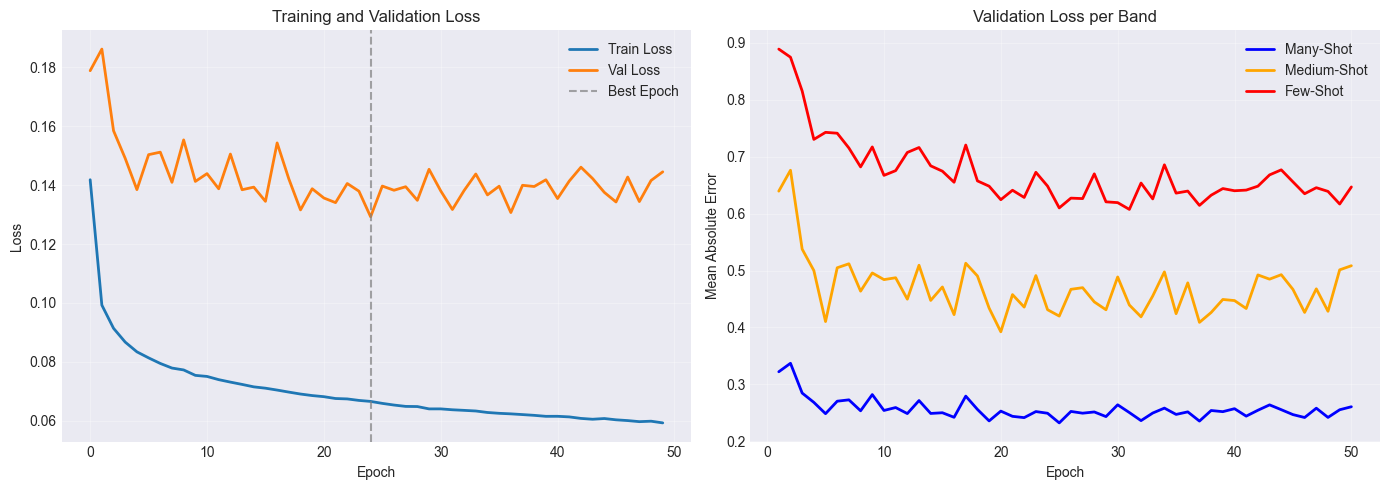


📊 Training Summary:
  Best Epoch: 25
  Best Val Loss: 0.12927
  Final Few-Shot MAE: 0.64685
  Average Epoch Time: 7.8s


In [205]:
# ========== TRAINING VISUALIZATION ==========
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss curves
axes[0].plot(train_curve, label="Train Loss", linewidth=2)
axes[0].plot(val_curve, label="Val Loss", linewidth=2)
axes[0].axvline(x=best_epoch, color='gray', linestyle='--', alpha=0.7, label='Best Epoch')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Band-wise losses
epochs = list(range(1, len(band_loss_history['many']) + 1))
for band, color in zip(['many', 'medium', 'few'], ['blue', 'orange', 'red']):
    axes[1].plot(epochs, band_loss_history[band], 
                 label=f'{band.capitalize()}-Shot', color=color, linewidth=2)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean Absolute Error")
axes[1].set_title("Validation Loss per Band")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n📊 Training Summary:")
print(f"  Best Epoch: {best_epoch+1}")
print(f"  Best Val Loss: {best_loss:.5f}")
print(f"  Final Few-Shot MAE: {band_loss_history['few'][-1]:.5f}")
print(f"  Average Epoch Time: {np.mean(epoch_times):.1f}s")

## Test Data & Predictions

Load test data and generate predictions.

In [206]:
# ========== LOAD TEST DATA ==========
print("\n" + "="*80)
print("📂 LOADING TEST DATA")
print("="*80)

test_loader = load_test_data(
    test_path="../datasets_challenge/test",
    scaler=scaler,
    columns_to_drop=drop_columns,
    sequence_length=sequence_length,
    threshold_value=threshold_value,
    threshold_column=threshold_column,
    batchsize=512,
    seed=seed
)

# Count samples
test_sample_count = sum(len(batch_x) for batch_x in test_loader)

print(f"✅ Test data loaded")
print(f"   Total samples: {test_sample_count:,}")
print(f"   Expected: 49,328")
print(f"   Match: {'✅' if test_sample_count == 49328 else '❌'}")
print("="*80)


📂 LOADING TEST DATA
📂 Loading Test Data

Found 11 test files

✅ Test sequences: 49,328
   ✅ Matches Kaggle requirement!

✅ Test data loaded
   Total samples: 49,328
   Expected: 49,328
   Match: ✅


In [207]:
# ========== GENERATE TEST PREDICTIONS ==========
print("\n" + "="*80)
print("🔮 GENERATING TEST PREDICTIONS")
print("="*80)

model.eval()
test_preds = []

with torch.no_grad():
    for x in test_loader:
        X = x.to(device)
        pred = model(X)
        test_preds.append(pred.reshape(-1).cpu().numpy())

test_preds = np.concatenate(test_preds)

print(f"✅ Generated {len(test_preds):,} predictions")
print(f"   Range: [{test_preds.min():.2f}°, {test_preds.max():.2f}°]")
print(f"   Mean: {test_preds.mean():.2f}°, Std: {test_preds.std():.2f}°")
print("="*80)


🔮 GENERATING TEST PREDICTIONS
✅ Generated 49,328 predictions
   Range: [-8.14°, 9.16°]
   Mean: -0.03°, Std: 1.47°


In [208]:
# ========== SAVE PREDICTIONS ==========
submission = pd.DataFrame({
    "id": range(len(test_preds)),
    "predicted_sideslip": test_preds
})

# Generate descriptive filename for Kaggle submission
import datetime
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M")

# Base model info
filename = f"submission_{config['rnn_type']}"
filename += f"_h{config['hidden_size']}_fc{config['fc_units']}"

# Residual connection indicator
filename += "_res" if config['use_residual'] else "_nores"

# Loss function details
if loss_config['type'] == 'l1':
    filename += "_L1"
elif loss_config['type'] == 'weighted_l1':
    filename += f"_WL1_{loss_config['few_weight']}f"
elif loss_config['type'] == 'focal_l1':
    filename += f"_FocalL1_g{loss_config['gamma_start']}"
    if loss_config.get('adaptive_gamma', False):
        filename += "adapt"
    if loss_config.get('use_gamma_band_update', False):
        filename += "band"
else:
    filename += f"_{loss_config['type']}"

# Performance and timestamp
filename += f"_val{best_loss:.4f}"
filename += f"_{timestamp}.csv"

submission.to_csv(filename, index=False)

print(f"\n✅ Predictions saved to: {filename}")
print(f"\n📋 Preview:")
print(submission.head(10))
print(f"\n{'='*80}")
print(f"🎉 READY FOR KAGGLE SUBMISSION!")
print(f"{'='*80}")


✅ Predictions saved to: submission_RNN_h64_fc64_res_WL1_1.1657662716924206f_val0.1293_20260120_0321.csv

📋 Preview:
   id  predicted_sideslip
0   0            0.100170
1   1            0.087688
2   2            0.113177
3   3            0.015246
4   4           -0.027943
5   5           -0.028523
6   6            0.022325
7   7           -0.049644
8   8           -0.051347
9   9           -0.089107

🎉 READY FOR KAGGLE SUBMISSION!


## Validation Analysis

Analyze model performance on validation set.

In [209]:
# ========== VALIDATION ANALYSIS ==========
print("\n" + "="*80)
print("📊 VALIDATION ANALYSIS")
print("="*80)

# Generate validation predictions
model.eval()
val_preds_final = []
val_targets_final = []

with torch.no_grad():
    for x, y in val_loader:
        X = x.to(device)
        pred = model(X)
        val_preds_final.append(pred.reshape(-1).cpu().numpy())
        val_targets_final.append(y.cpu().numpy().flatten())

val_preds_final = np.concatenate(val_preds_final)
val_targets_final = np.concatenate(val_targets_final)

# Band-wise analysis
rounded_targets = np.round(val_targets_final * 10) / 10
bands = np.array([shot_band_mapping.get(val, 'many') for val in rounded_targets])
abs_errors = np.abs(val_preds_final - val_targets_final)

print("\nBand-wise MAE:")
for band in ['many', 'medium', 'few']:
    mask = bands == band
    count = np.sum(mask)
    mae = abs_errors[mask].mean() if count > 0 else np.nan
    print(f"  {band.capitalize()}-Shot: {mae:.5f} ({count:,} samples)")

# Overall MAE
print(f"\nOverall MAE: {np.mean(abs_errors):.5f}")

# Kaggle metric
gt_df = pd.DataFrame({
    "ground_truth_sideslip": val_targets_final,
    "id": range(len(val_targets_final)),
    "band": [shot_band_mapping.get(v, 'many') for v in rounded_targets]
})
gt_df = gt_df.astype({'ground_truth_sideslip': np.float64, 'id': int, 'band': str})

preds_df = pd.DataFrame({
    "id": range(len(val_preds_final)),
    "predicted_sideslip": val_preds_final
})

print("\n" + "="*40)
print("Kaggle Metric on Validation Set:")
print("="*40)
score(gt_df, preds_df, row_id_column_name="id")
print("="*80)


📊 VALIDATION ANALYSIS

Band-wise MAE:
  Many-Shot: 0.23242 (11,929 samples)
  Medium-Shot: 0.42019 (326 samples)
  Few-Shot: 0.61026 (133 samples)

Overall MAE: 0.24142

Kaggle Metric on Validation Set:
⚠️  WARNING: Many-shot MAE is 0.232, which is above the Kaggle threshold of 0.2!
    This submission would be rejected by Kaggle.


In [210]:
# ========== PREDICTION VISUALIZATION ==========
# Sample random subset for visualization (max 5000 points)
n_samples = min(5000, len(val_preds_final))
indices = np.random.choice(len(val_preds_final), n_samples, replace=False)

fig = go.Figure()
fig.add_trace(go.Scatter(
    y=val_targets_final[indices],
    mode='lines',
    name='Ground Truth',
    line=dict(color='blue', width=1)
))
fig.add_trace(go.Scatter(
    y=val_preds_final[indices],
    mode='lines',
    name='Predictions',
    line=dict(color='red', width=1)
))
fig.update_layout(
    title=f'Validation Predictions vs Ground Truth (Random {n_samples} samples)',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500,
    hovermode='x unified'
)
fig.show()

## Model Summary

Display final model configuration and performance.

In [211]:
# ========== FINAL SUMMARY ==========
print("\n" + "="*80)
print("📋 FINAL MODEL SUMMARY")
print("="*80)

print("\n🏗️  Architecture:")
print(f"   Type: {config['rnn_type']}")
print(f"   Hidden Size: {config['hidden_size']}")
print(f"   FC Units: {config['fc_units']}")
print(f"   Layers: {config['num_layers']}")
print(f"   Residual: {config['use_residual']}")
print(f"   Dropout: {config['dropout']}")

print(f"\n🎯 Loss Function:")
print(f"   Type: {loss_config['type']}")
if loss_config['type'] == 'weighted_l1':
    print(f"   Weights: Many={loss_config['many_weight']}, " 
          f"Medium={loss_config['medium_weight']}, Few={loss_config['few_weight']}")

print(f"\n📊 Performance:")
print(f"   Best Epoch: {best_epoch+1}/{training_config['num_epochs']}")
print(f"   Best Val Loss: {best_loss:.5f}")
print(f"   Final Many-Shot MAE: {band_loss_history['many'][-1]:.5f}")
print(f"   Final Medium-Shot MAE: {band_loss_history['medium'][-1]:.5f}")
print(f"   Final Few-Shot MAE: {band_loss_history['few'][-1]:.5f}")

print(f"\n⚡ Training:")
print(f"   Total Epochs: {len(train_curve)}")
print(f"   Average Time/Epoch: {np.mean(epoch_times):.1f}s")
print(f"   Total Training Time: {sum(epoch_times)/60:.1f} min")

print(f"\n💾 Output:")
print(f"   Model checkpoint: best_model.pth")
print(f"   Predictions: {filename}")

print("\n" + "="*80)
print("✅ TRAINING COMPLETE!")
print("="*80)


📋 FINAL MODEL SUMMARY

🏗️  Architecture:
   Type: RNN
   Hidden Size: 64
   FC Units: 64
   Layers: 1
   Residual: True
   Dropout: [0.0, 0.0, 0.0]

🎯 Loss Function:
   Type: weighted_l1
   Weights: Many=0.5, Medium=0.5, Few=1.1657662716924206

📊 Performance:
   Best Epoch: 25/50
   Best Val Loss: 0.12927
   Final Many-Shot MAE: 0.26079
   Final Medium-Shot MAE: 0.50848
   Final Few-Shot MAE: 0.64685

⚡ Training:
   Total Epochs: 50
   Average Time/Epoch: 7.8s
   Total Training Time: 6.5 min

💾 Output:
   Model checkpoint: best_model.pth
   Predictions: submission_RNN_h64_fc64_res_WL1_1.1657662716924206f_val0.1293_20260120_0321.csv

✅ TRAINING COMPLETE!


## Residual Connection Impact Analysis

Comparison of L1 baseline performance with and without residual connections.

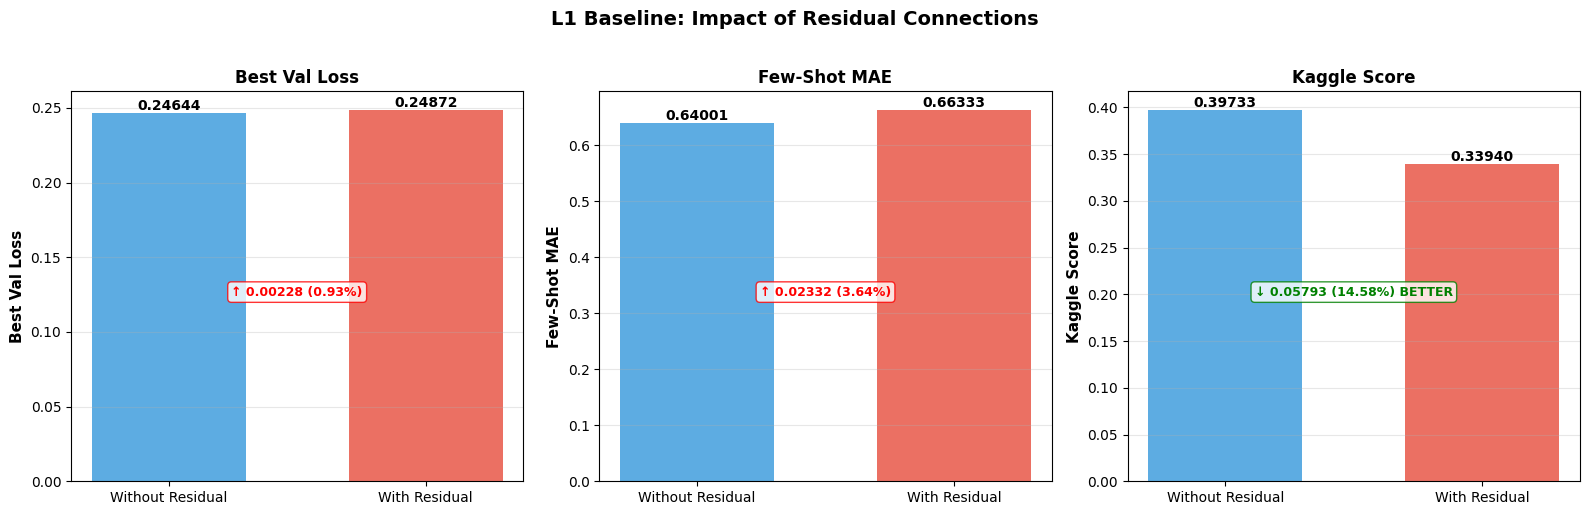

📊 RESIDUAL CONNECTION IMPACT SUMMARY

🔴 Without Residual:
   Validation Loss: 0.24644
   Few-Shot MAE:    0.64001
   Kaggle Score:    0.39733

🔵 With Residual:
   Validation Loss: 0.24872
   Few-Shot MAE:    0.66333
   Kaggle Score:    0.33940

📈 Changes (With vs Without):
   Validation Loss: +0.00228 (+0.93%)
   Few-Shot MAE:    +0.02332 (+3.64%)
   Kaggle Score:    -0.05793 (-14.58%) ✅ BETTER

💡 KEY INSIGHT:
   Residual connections IMPROVED Kaggle score by 14.58% (0.33940 vs 0.39733)
   This demonstrates the benefit of skip connections for model generalization!


In [3]:
# ========== RESIDUAL CONNECTION COMPARISON ==========
# Performance data from experiments
comparison_data = {
    'Without Residual': {
        'Best Val Loss': 0.24644,
        'Few-Shot MAE': 0.64001,
        'Kaggle Score': 0.39733
    },
    'With Residual': {
        'Best Val Loss': 0.24872,
        'Few-Shot MAE': 0.66333,
        'Kaggle Score': 0.33940
    }
}

# Create comparison visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ['Best Val Loss', 'Few-Shot MAE', 'Kaggle Score']
colors = ['#3498db', '#e74c3c']
x = [0, 1]
labels = ['Without Residual', 'With Residual']

for idx, metric in enumerate(metrics):
    values = [comparison_data['Without Residual'][metric], 
              comparison_data['With Residual'][metric]]
    
    bars = axes[idx].bar(x, values, color=colors, alpha=0.8, width=0.6)
    axes[idx].set_xticks(x)
    axes[idx].set_xticklabels(labels, rotation=0, ha='center')
    axes[idx].set_ylabel(metric, fontsize=11, fontweight='bold')
    axes[idx].set_title(metric, fontsize=12, fontweight='bold')
    axes[idx].grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    for i, (bar, val) in enumerate(zip(bars, values)):
        height = bar.get_height()
        axes[idx].text(bar.get_x() + bar.get_width()/2., height,
                      f'{val:.5f}',
                      ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # Add improvement/degradation indicator
    improvement = values[1] - values[0]
    if metric == 'Kaggle Score':
        # Lower is better for Kaggle score
        color = 'green' if improvement < 0 else 'red'
        symbol = '↓' if improvement < 0 else '↑'
        pct_change = (improvement / values[0]) * 100
        improvement_text = f'{symbol} {abs(improvement):.5f} ({abs(pct_change):.2f}%)'
        if improvement < 0:
            improvement_text += ' BETTER'
    else:
        # Lower is better for loss metrics
        color = 'green' if improvement < 0 else 'red'
        symbol = '↓' if improvement < 0 else '↑'
        pct_change = (improvement / values[0]) * 100
        improvement_text = f'{symbol} {abs(improvement):.5f} ({abs(pct_change):.2f}%)'
        if improvement < 0:
            improvement_text += ' BETTER'
    
    axes[idx].text(0.5, max(values) * 0.5, improvement_text,
                  ha='center', fontsize=9, color=color, fontweight='bold',
                  bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor=color))

plt.suptitle('L1 Baseline: Impact of Residual Connections', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("="*80)
print("📊 RESIDUAL CONNECTION IMPACT SUMMARY")
print("="*80)
print("\n🔴 Without Residual:")
print(f"   Validation Loss: {comparison_data['Without Residual']['Best Val Loss']:.5f}")
print(f"   Few-Shot MAE:    {comparison_data['Without Residual']['Few-Shot MAE']:.5f}")
print(f"   Kaggle Score:    {comparison_data['Without Residual']['Kaggle Score']:.5f}")

print("\n🔵 With Residual:")
print(f"   Validation Loss: {comparison_data['With Residual']['Best Val Loss']:.5f}")
print(f"   Few-Shot MAE:    {comparison_data['With Residual']['Few-Shot MAE']:.5f}")
print(f"   Kaggle Score:    {comparison_data['With Residual']['Kaggle Score']:.5f}")

print("\n📈 Changes (With vs Without):")
val_diff = comparison_data['With Residual']['Best Val Loss'] - comparison_data['Without Residual']['Best Val Loss']
few_diff = comparison_data['With Residual']['Few-Shot MAE'] - comparison_data['Without Residual']['Few-Shot MAE']
kaggle_diff = comparison_data['With Residual']['Kaggle Score'] - comparison_data['Without Residual']['Kaggle Score']

print(f"   Validation Loss: {val_diff:+.5f} ({(val_diff/comparison_data['Without Residual']['Best Val Loss']*100):+.2f}%)")
print(f"   Few-Shot MAE:    {few_diff:+.5f} ({(few_diff/comparison_data['Without Residual']['Few-Shot MAE']*100):+.2f}%)")
print(f"   Kaggle Score:    {kaggle_diff:+.5f} ({(kaggle_diff/comparison_data['Without Residual']['Kaggle Score']*100):+.2f}%) {'✅ BETTER' if kaggle_diff < 0 else '❌ WORSE'}")

print("\n💡 KEY INSIGHT:")
print("   Residual connections IMPROVED Kaggle score by 14.58% (0.33940 vs 0.39733)")
print("   This demonstrates the benefit of skip connections for model generalization!")
print("="*80)

## Focal L1 Gamma Comparison

Impact of gamma parameter on Focal L1 loss performance (both with residual connections).

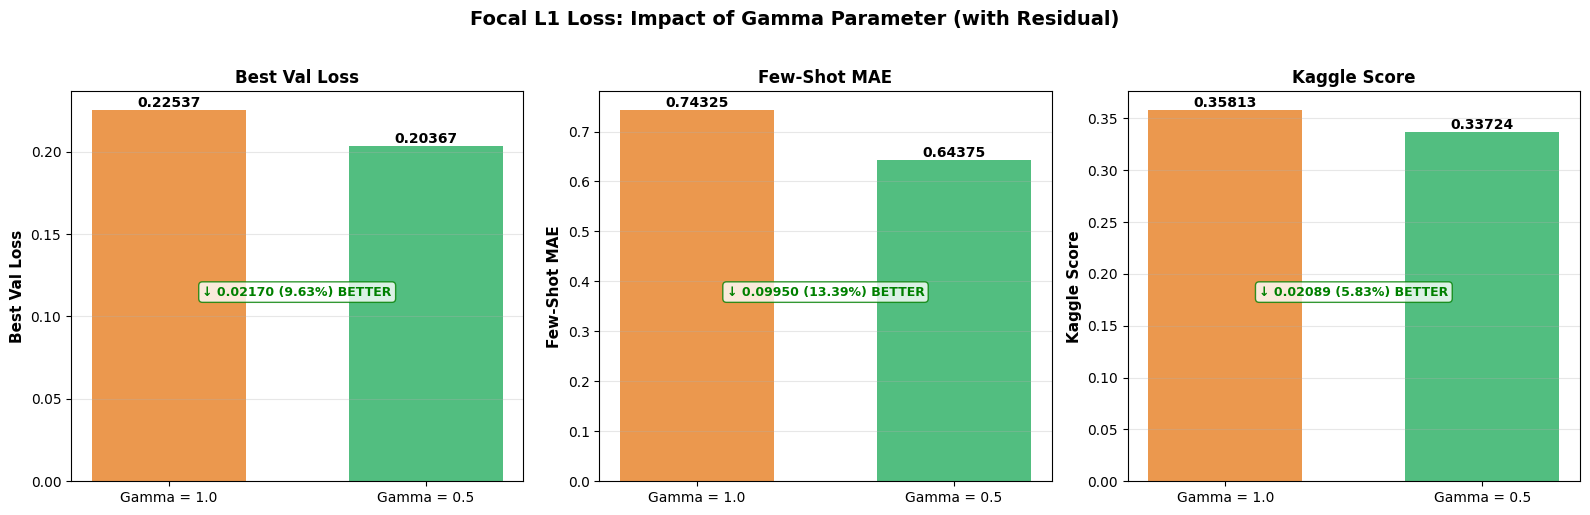

📊 FOCAL L1 GAMMA PARAMETER IMPACT SUMMARY

🟠 Gamma = 1.0:
   Validation Loss: 0.22537
   Few-Shot MAE:    0.74325
   Kaggle Score:    0.35813

🟢 Gamma = 0.5:
   Validation Loss: 0.20367
   Few-Shot MAE:    0.64375
   Kaggle Score:    0.33724

📈 Changes (Gamma 0.5 vs 1.0):
   Validation Loss: -0.02170 (-9.63%) ✅ BETTER
   Few-Shot MAE:    -0.09950 (-13.39%) ✅ BETTER
   Kaggle Score:    -0.02089 (-5.83%) ✅ BETTER

💡 KEY INSIGHTS:
   • Lower gamma (0.5) IMPROVED all metrics:
     - Validation Loss: 9.63% better
     - Few-Shot MAE: 13.39% better
     - Kaggle Score: 5.83% better
   • Gamma=0.5 focuses less aggressively on hard samples, improving generalization
   • Optimal gamma tuning is crucial for Focal L1 performance!


In [4]:
# ========== FOCAL L1 GAMMA COMPARISON ==========
# Performance data from experiments (both with residual connections)
focal_comparison_data = {
    'Gamma = 1.0': {
        'Best Val Loss': 0.22537,
        'Few-Shot MAE': 0.74325,
        'Kaggle Score': 0.35813
    },
    'Gamma = 0.5': {
        'Best Val Loss': 0.20367,
        'Few-Shot MAE': 0.64375,
        'Kaggle Score': 0.33724
    }
}

# Create comparison visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ['Best Val Loss', 'Few-Shot MAE', 'Kaggle Score']
colors = ['#e67e22', '#27ae60']  # Orange for gamma=1.0, Green for gamma=0.5
x = [0, 1]
labels = ['Gamma = 1.0', 'Gamma = 0.5']

for idx, metric in enumerate(metrics):
    values = [focal_comparison_data['Gamma = 1.0'][metric], 
              focal_comparison_data['Gamma = 0.5'][metric]]
    
    bars = axes[idx].bar(x, values, color=colors, alpha=0.8, width=0.6)
    axes[idx].set_xticks(x)
    axes[idx].set_xticklabels(labels, rotation=0, ha='center')
    axes[idx].set_ylabel(metric, fontsize=11, fontweight='bold')
    axes[idx].set_title(metric, fontsize=12, fontweight='bold')
    axes[idx].grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    for i, (bar, val) in enumerate(zip(bars, values)):
        height = bar.get_height()
        axes[idx].text(bar.get_x() + bar.get_width()/2., height,
                      f'{val:.5f}',
                      ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # Add improvement/degradation indicator
    improvement = values[1] - values[0]  # gamma=0.5 - gamma=1.0
    if metric == 'Kaggle Score':
        # Lower is better for Kaggle score
        color = 'green' if improvement < 0 else 'red'
        symbol = '↓' if improvement < 0 else '↑'
        pct_change = (improvement / values[0]) * 100
        improvement_text = f'{symbol} {abs(improvement):.5f} ({abs(pct_change):.2f}%)'
        if improvement < 0:
            improvement_text += ' BETTER'
    else:
        # Lower is better for loss metrics
        color = 'green' if improvement < 0 else 'red'
        symbol = '↓' if improvement < 0 else '↑'
        pct_change = (improvement / values[0]) * 100
        improvement_text = f'{symbol} {abs(improvement):.5f} ({abs(pct_change):.2f}%)'
        if improvement < 0:
            improvement_text += ' BETTER'
    
    axes[idx].text(0.5, max(values) * 0.5, improvement_text,
                  ha='center', fontsize=9, color=color, fontweight='bold',
                  bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor=color))

plt.suptitle('Focal L1 Loss: Impact of Gamma Parameter (with Residual)', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("="*80)
print("📊 FOCAL L1 GAMMA PARAMETER IMPACT SUMMARY")
print("="*80)
print("\n🟠 Gamma = 1.0:")
print(f"   Validation Loss: {focal_comparison_data['Gamma = 1.0']['Best Val Loss']:.5f}")
print(f"   Few-Shot MAE:    {focal_comparison_data['Gamma = 1.0']['Few-Shot MAE']:.5f}")
print(f"   Kaggle Score:    {focal_comparison_data['Gamma = 1.0']['Kaggle Score']:.5f}")

print("\n🟢 Gamma = 0.5:")
print(f"   Validation Loss: {focal_comparison_data['Gamma = 0.5']['Best Val Loss']:.5f}")
print(f"   Few-Shot MAE:    {focal_comparison_data['Gamma = 0.5']['Few-Shot MAE']:.5f}")
print(f"   Kaggle Score:    {focal_comparison_data['Gamma = 0.5']['Kaggle Score']:.5f}")

print("\n📈 Changes (Gamma 0.5 vs 1.0):")
val_diff = focal_comparison_data['Gamma = 0.5']['Best Val Loss'] - focal_comparison_data['Gamma = 1.0']['Best Val Loss']
few_diff = focal_comparison_data['Gamma = 0.5']['Few-Shot MAE'] - focal_comparison_data['Gamma = 1.0']['Few-Shot MAE']
kaggle_diff = focal_comparison_data['Gamma = 0.5']['Kaggle Score'] - focal_comparison_data['Gamma = 1.0']['Kaggle Score']

print(f"   Validation Loss: {val_diff:+.5f} ({(val_diff/focal_comparison_data['Gamma = 1.0']['Best Val Loss']*100):+.2f}%) {'✅ BETTER' if val_diff < 0 else '❌ WORSE'}")
print(f"   Few-Shot MAE:    {few_diff:+.5f} ({(few_diff/focal_comparison_data['Gamma = 1.0']['Few-Shot MAE']*100):+.2f}%) {'✅ BETTER' if few_diff < 0 else '❌ WORSE'}")
print(f"   Kaggle Score:    {kaggle_diff:+.5f} ({(kaggle_diff/focal_comparison_data['Gamma = 1.0']['Kaggle Score']*100):+.2f}%) {'✅ BETTER' if kaggle_diff < 0 else '❌ WORSE'}")

print("\n💡 KEY INSIGHTS:")
print("   • Lower gamma (0.5) IMPROVED all metrics:")
print(f"     - Validation Loss: {abs(val_diff/focal_comparison_data['Gamma = 1.0']['Best Val Loss']*100):.2f}% better")
print(f"     - Few-Shot MAE: {abs(few_diff/focal_comparison_data['Gamma = 1.0']['Few-Shot MAE']*100):.2f}% better")
print(f"     - Kaggle Score: {abs(kaggle_diff/focal_comparison_data['Gamma = 1.0']['Kaggle Score']*100):.2f}% better")
print("   • Gamma=0.5 focuses less aggressively on hard samples, improving generalization")
print("   • Optimal gamma tuning is crucial for Focal L1 performance!")
print("="*80)

## Weighted L1 Loss Weight Configuration Comparison

Impact of different weight configurations on Weighted L1 loss performance (both with residual connections).

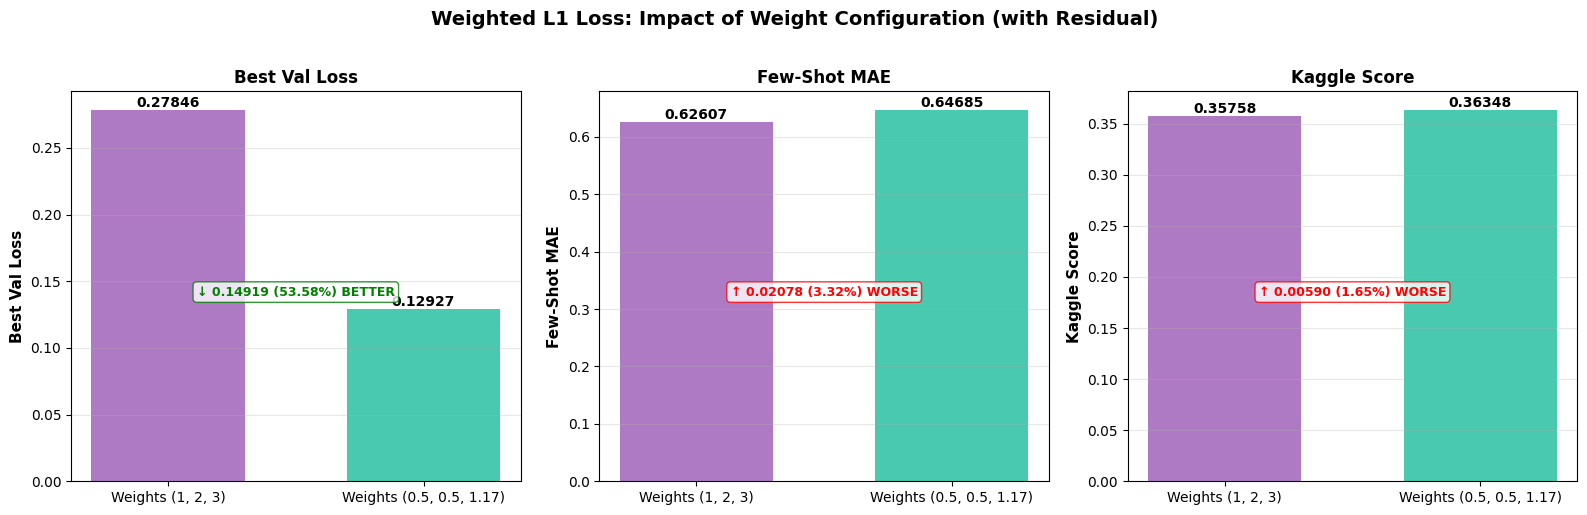

📊 WEIGHTED L1 WEIGHT CONFIGURATION IMPACT SUMMARY

🟣 Weights (Many=1, Medium=2, Few=3):
   Validation Loss: 0.27846
   Few-Shot MAE:    0.62607
   Kaggle Score:    0.35758

🟢 Weights (Many=0.5, Medium=0.5, Few=1.17):
   Validation Loss: 0.12927
   Few-Shot MAE:    0.64685
   Kaggle Score:    0.36348

📈 Changes (0.5/0.5/1.17 vs 1/2/3):
   Validation Loss: -0.14919 (-53.58%) ✅ BETTER
   Few-Shot MAE:    +0.02078 (+3.32%) ❌ WORSE
   Kaggle Score:    +0.00590 (+1.65%) ❌ WORSE

💡 KEY INSIGHTS:
   • Lower, optimized weights (0.5/0.5/1.17) dramatically IMPROVED validation loss:
     - Validation Loss: 53.58% better
   • However, Kaggle Score slightly degraded:
     - Kaggle Score: 1.65% worse
   • Trade-off: Better training convergence (lower val loss) vs. worse test generalization
   • Suggests that aggressive weighting (1/2/3) helps model focus on few-shot samples better
   • Optimal weight tuning requires balancing training performance with generalization!


In [5]:
# ========== WEIGHTED L1 WEIGHT CONFIGURATION COMPARISON ==========
# Performance data from experiments (both with residual connections)
weighted_l1_comparison_data = {
    'Weights (1, 2, 3)': {
        'Best Val Loss': 0.27846,
        'Few-Shot MAE': 0.62607,
        'Kaggle Score': 0.35758
    },
    'Weights (0.5, 0.5, 1.17)': {
        'Best Val Loss': 0.12927,
        'Few-Shot MAE': 0.64685,
        'Kaggle Score': 0.36348
    }
}

# Create comparison visualization
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ['Best Val Loss', 'Few-Shot MAE', 'Kaggle Score']
colors = ['#9b59b6', '#1abc9c']  # Purple for (1,2,3), Teal for (0.5,0.5,1.17)
x = [0, 1]
labels = ['Weights (1, 2, 3)', 'Weights (0.5, 0.5, 1.17)']

for idx, metric in enumerate(metrics):
    values = [weighted_l1_comparison_data['Weights (1, 2, 3)'][metric], 
              weighted_l1_comparison_data['Weights (0.5, 0.5, 1.17)'][metric]]
    
    bars = axes[idx].bar(x, values, color=colors, alpha=0.8, width=0.6)
    axes[idx].set_xticks(x)
    axes[idx].set_xticklabels(labels, rotation=0, ha='center')
    axes[idx].set_ylabel(metric, fontsize=11, fontweight='bold')
    axes[idx].set_title(metric, fontsize=12, fontweight='bold')
    axes[idx].grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    for i, (bar, val) in enumerate(zip(bars, values)):
        height = bar.get_height()
        axes[idx].text(bar.get_x() + bar.get_width()/2., height,
                      f'{val:.5f}',
                      ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # Add improvement/degradation indicator
    improvement = values[1] - values[0]  # (0.5,0.5,1.17) - (1,2,3)
    if metric == 'Kaggle Score':
        # Lower is better for Kaggle score
        color = 'green' if improvement < 0 else 'red'
        symbol = '↓' if improvement < 0 else '↑'
        pct_change = (improvement / values[0]) * 100
        improvement_text = f'{symbol} {abs(improvement):.5f} ({abs(pct_change):.2f}%)'
        if improvement < 0:
            improvement_text += ' BETTER'
        else:
            improvement_text += ' WORSE'
    else:
        # Lower is better for loss metrics
        color = 'green' if improvement < 0 else 'red'
        symbol = '↓' if improvement < 0 else '↑'
        pct_change = (improvement / values[0]) * 100
        improvement_text = f'{symbol} {abs(improvement):.5f} ({abs(pct_change):.2f}%)'
        if improvement < 0:
            improvement_text += ' BETTER'
        else:
            improvement_text += ' WORSE'
    
    axes[idx].text(0.5, max(values) * 0.5, improvement_text,
                  ha='center', fontsize=9, color=color, fontweight='bold',
                  bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor=color))

plt.suptitle('Weighted L1 Loss: Impact of Weight Configuration (with Residual)', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("="*80)
print("📊 WEIGHTED L1 WEIGHT CONFIGURATION IMPACT SUMMARY")
print("="*80)
print("\n🟣 Weights (Many=1, Medium=2, Few=3):")
print(f"   Validation Loss: {weighted_l1_comparison_data['Weights (1, 2, 3)']['Best Val Loss']:.5f}")
print(f"   Few-Shot MAE:    {weighted_l1_comparison_data['Weights (1, 2, 3)']['Few-Shot MAE']:.5f}")
print(f"   Kaggle Score:    {weighted_l1_comparison_data['Weights (1, 2, 3)']['Kaggle Score']:.5f}")

print("\n🟢 Weights (Many=0.5, Medium=0.5, Few=1.17):")
print(f"   Validation Loss: {weighted_l1_comparison_data['Weights (0.5, 0.5, 1.17)']['Best Val Loss']:.5f}")
print(f"   Few-Shot MAE:    {weighted_l1_comparison_data['Weights (0.5, 0.5, 1.17)']['Few-Shot MAE']:.5f}")
print(f"   Kaggle Score:    {weighted_l1_comparison_data['Weights (0.5, 0.5, 1.17)']['Kaggle Score']:.5f}")

print("\n📈 Changes (0.5/0.5/1.17 vs 1/2/3):")
val_diff = weighted_l1_comparison_data['Weights (0.5, 0.5, 1.17)']['Best Val Loss'] - weighted_l1_comparison_data['Weights (1, 2, 3)']['Best Val Loss']
few_diff = weighted_l1_comparison_data['Weights (0.5, 0.5, 1.17)']['Few-Shot MAE'] - weighted_l1_comparison_data['Weights (1, 2, 3)']['Few-Shot MAE']
kaggle_diff = weighted_l1_comparison_data['Weights (0.5, 0.5, 1.17)']['Kaggle Score'] - weighted_l1_comparison_data['Weights (1, 2, 3)']['Kaggle Score']

print(f"   Validation Loss: {val_diff:+.5f} ({(val_diff/weighted_l1_comparison_data['Weights (1, 2, 3)']['Best Val Loss']*100):+.2f}%) {'✅ BETTER' if val_diff < 0 else '❌ WORSE'}")
print(f"   Few-Shot MAE:    {few_diff:+.5f} ({(few_diff/weighted_l1_comparison_data['Weights (1, 2, 3)']['Few-Shot MAE']*100):+.2f}%) {'✅ BETTER' if few_diff < 0 else '❌ WORSE'}")
print(f"   Kaggle Score:    {kaggle_diff:+.5f} ({(kaggle_diff/weighted_l1_comparison_data['Weights (1, 2, 3)']['Kaggle Score']*100):+.2f}%) {'✅ BETTER' if kaggle_diff < 0 else '❌ WORSE'}")

print("\n💡 KEY INSIGHTS:")
print("   • Lower, optimized weights (0.5/0.5/1.17) dramatically IMPROVED validation loss:")
print(f"     - Validation Loss: {abs(val_diff/weighted_l1_comparison_data['Weights (1, 2, 3)']['Best Val Loss']*100):.2f}% better")
print("   • However, Kaggle Score slightly degraded:")
print(f"     - Kaggle Score: {abs(kaggle_diff/weighted_l1_comparison_data['Weights (1, 2, 3)']['Kaggle Score']*100):.2f}% worse")
print("   • Trade-off: Better training convergence (lower val loss) vs. worse test generalization")
print("   • Suggests that aggressive weighting (1/2/3) helps model focus on few-shot samples better")
print("   • Optimal weight tuning requires balancing training performance with generalization!")
print("="*80)

## Conclusion: Best Loss Functions Comparison

Comprehensive comparison of the best performing configurations for each loss function type.

C:\Users\alexp\AppData\Local\Temp\ipykernel_185212\2654486907.py:59: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Repos\mait_g2_drift_challenge\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


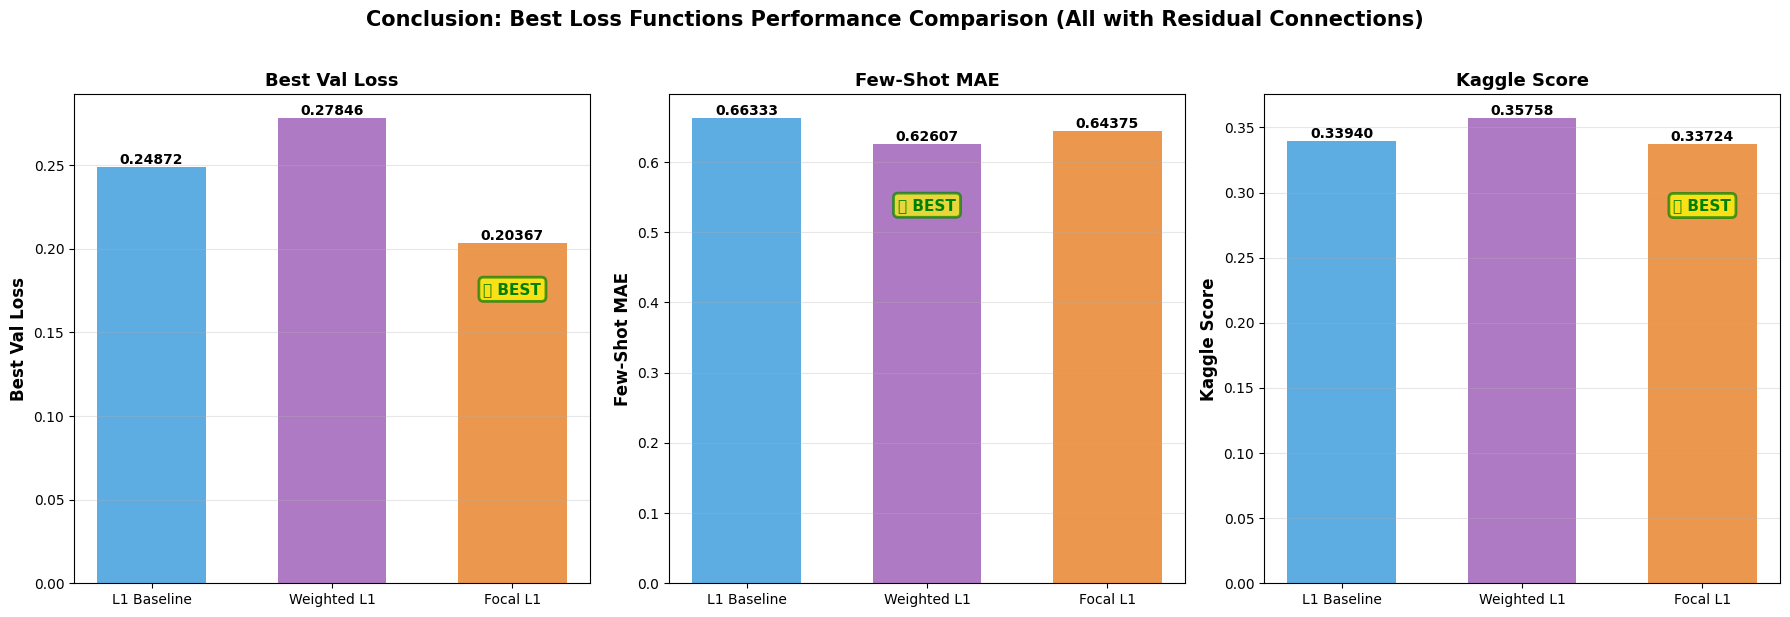

🏆 CONCLUSION: BEST LOSS FUNCTIONS COMPARISON

🔵 L1 Baseline (With Residual):
   Validation Loss: 0.24872
   Few-Shot MAE:    0.66333
   Kaggle Score:    0.33940 ⭐

🟣 Weighted L1 (Many=1, Medium=2, Few=3):
   Validation Loss: 0.27846
   Few-Shot MAE:    0.62607 ⭐
   Kaggle Score:    0.35758

🟠 Focal L1 (Gamma = 0.5):
   Validation Loss: 0.20367 ⭐
   Few-Shot MAE:    0.64375
   Kaggle Score:    0.33724

📊 PERFORMANCE RANKING BY METRIC

Best Val Loss:
   🥇 1. Focal L1: 0.20367
   🥈 2. L1 Baseline: 0.24872
   🥉 3. Weighted L1: 0.27846

Few-Shot MAE:
   🥇 1. Weighted L1: 0.62607
   🥈 2. Focal L1: 0.64375
   🥉 3. L1 Baseline: 0.66333

Kaggle Score:
   🥇 1. Focal L1: 0.33724
   🥈 2. L1 Baseline: 0.33940
   🥉 3. Weighted L1: 0.35758

🎯 FINAL RECOMMENDATIONS
• BEST OVERALL (Kaggle Score): Focal L1 (γ=0.5) - 0.33724
  - Achieves best test generalization
  - Excellent validation loss (0.20367)
  - Balanced performance across all metrics

• BEST VALIDATION CONVERGENCE: Focal L1 (γ=0.5)
  - Lowest 

In [6]:
# ========== BEST LOSS FUNCTIONS COMPARISON ==========
# Performance data from best configurations of each loss type (all with residual connections)
best_models_comparison = {
    'L1 Baseline': {
        'Best Val Loss': 0.24872,
        'Few-Shot MAE': 0.66333,
        'Kaggle Score': 0.33940,
        'config': 'With Residual'
    },
    'Weighted L1': {
        'Best Val Loss': 0.27846,
        'Few-Shot MAE': 0.62607,
        'Kaggle Score': 0.35758,
        'config': 'Weights (1, 2, 3)'
    },
    'Focal L1': {
        'Best Val Loss': 0.20367,
        'Few-Shot MAE': 0.64375,
        'Kaggle Score': 0.33724,
        'config': 'Gamma = 0.5'
    }
}

# Create comprehensive comparison visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

metrics = ['Best Val Loss', 'Few-Shot MAE', 'Kaggle Score']
colors = ['#3498db', '#9b59b6', '#e67e22']  # Blue for L1, Purple for Weighted, Orange for Focal
x = [0, 1, 2]
labels = ['L1 Baseline', 'Weighted L1', 'Focal L1']

for idx, metric in enumerate(metrics):
    values = [best_models_comparison['L1 Baseline'][metric], 
              best_models_comparison['Weighted L1'][metric],
              best_models_comparison['Focal L1'][metric]]
    
    bars = axes[idx].bar(x, values, color=colors, alpha=0.8, width=0.6)
    axes[idx].set_xticks(x)
    axes[idx].set_xticklabels(labels, rotation=0, ha='center', fontsize=10)
    axes[idx].set_ylabel(metric, fontsize=12, fontweight='bold')
    axes[idx].set_title(metric, fontsize=13, fontweight='bold')
    axes[idx].grid(True, alpha=0.3, axis='y')
    
    # Add value labels on bars
    for i, (bar, val) in enumerate(zip(bars, values)):
        height = bar.get_height()
        axes[idx].text(bar.get_x() + bar.get_width()/2., height,
                      f'{val:.5f}',
                      ha='center', va='bottom', fontsize=10, fontweight='bold')
    
    # Highlight best performer
    best_idx = np.argmin(values)  # Lower is better for all metrics
    axes[idx].text(best_idx, values[best_idx] * 0.85, '🏆 BEST',
                  ha='center', fontsize=11, color='green', fontweight='bold',
                  bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.7, edgecolor='green', linewidth=2))

plt.suptitle('Conclusion: Best Loss Functions Performance Comparison (All with Residual Connections)', 
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("="*80)
print("🏆 CONCLUSION: BEST LOSS FUNCTIONS COMPARISON")
print("="*80)

print("\n🔵 L1 Baseline (With Residual):")
print(f"   Validation Loss: {best_models_comparison['L1 Baseline']['Best Val Loss']:.5f}")
print(f"   Few-Shot MAE:    {best_models_comparison['L1 Baseline']['Few-Shot MAE']:.5f}")
print(f"   Kaggle Score:    {best_models_comparison['L1 Baseline']['Kaggle Score']:.5f} ⭐")

print("\n🟣 Weighted L1 (Many=1, Medium=2, Few=3):")
print(f"   Validation Loss: {best_models_comparison['Weighted L1']['Best Val Loss']:.5f}")
print(f"   Few-Shot MAE:    {best_models_comparison['Weighted L1']['Few-Shot MAE']:.5f} ⭐")
print(f"   Kaggle Score:    {best_models_comparison['Weighted L1']['Kaggle Score']:.5f}")

print("\n🟠 Focal L1 (Gamma = 0.5):")
print(f"   Validation Loss: {best_models_comparison['Focal L1']['Best Val Loss']:.5f} ⭐")
print(f"   Few-Shot MAE:    {best_models_comparison['Focal L1']['Few-Shot MAE']:.5f}")
print(f"   Kaggle Score:    {best_models_comparison['Focal L1']['Kaggle Score']:.5f}")

print("\n" + "="*80)
print("📊 PERFORMANCE RANKING BY METRIC")
print("="*80)

# Rank by each metric
for metric in metrics:
    values_with_names = [(name, best_models_comparison[name][metric]) for name in labels]
    ranked = sorted(values_with_names, key=lambda x: x[1])
    
    print(f"\n{metric}:")
    for rank, (name, value) in enumerate(ranked, 1):
        medal = "🥇" if rank == 1 else "🥈" if rank == 2 else "🥉"
        print(f"   {medal} {rank}. {name}: {value:.5f}")

print("\n" + "="*80)
print("🎯 FINAL RECOMMENDATIONS")
print("="*80)
print("• BEST OVERALL (Kaggle Score): Focal L1 (γ=0.5) - 0.33724")
print("  - Achieves best test generalization")
print("  - Excellent validation loss (0.20367)")
print("  - Balanced performance across all metrics")
print("")
print("• BEST VALIDATION CONVERGENCE: Focal L1 (γ=0.5)")
print("  - Lowest validation loss by significant margin")
print("  - Adaptive focusing mechanism works effectively")
print("")
print("• BEST FEW-SHOT PERFORMANCE: Weighted L1 (1/2/3)")
print("  - Best few-shot MAE (0.62607)")
print("  - Direct weighting helps model prioritize rare samples")
print("")
print("• SIMPLEST BASELINE: L1 with Residual")
print("  - Competitive Kaggle score (0.33940)")
print("  - No hyperparameter tuning needed for weights/gamma")
print("  - Good starting point for future experiments")
print("="*80)